# VOLTRELAY ENERGY – DATA ANALYTICS HACKATHON

## Step 1: Data Understanding & Project Initialization

### Business Context
VoltRelay Energy operates an EV battery-swapping network across six Indian cities.

### Business Problems
- Increasing service failures
- Declining new-rider retention
- Eroding contribution margin per swap

### Project Objective
Analyze operational, customer, battery, station and financial data to identify the factors associated with service failures, rider churn and declining profitability.

### Analytical Approach
1. Project and Environment Setup
2. Data Loading and Verification
3. Data Understanding
4. Data Quality Assessment
5. Exploratory Data Analysis
6. Root Cause Analysis
7. Business Analysis
8. Recommendations

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy and Google Colab.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
batteries = pd.read_csv("/content/batteries.csv")
city_daily_context = pd.read_csv("/content/city_daily_context.csv")
fleet_partners = pd.read_csv("/content/fleet_partners.csv")
riders = pd.read_csv("/content/riders.csv")
station_hourly_status = pd.read_csv("/content/station_hourly_status.csv")
stations = pd.read_csv("/content/stations.csv")
support_tickets = pd.read_csv("/content/support_tickets.csv")
swap_events = pd.read_csv("/content/swap_events.csv")

# ## Step 2: Data Understanding

In this step, we performed an initial inspection of all eight datasets.

The following checks were performed:

- Dataset shape and dimensions
- Column names and data types
- Duplicate records
- Missing values
- First five rows of each dataset

These checks help us understand the structure and quality of the data before starting detailed analysis.

# 1. Shape of all CSV files

In [3]:
print("SHAPE OF ALL DATASETS")

print("Batteries:", batteries.shape)
print("City Daily Context:", city_daily_context.shape)
print("Fleet Partners:", fleet_partners.shape)
print("Riders:", riders.shape)
print("Station Hourly Status:", station_hourly_status.shape)
print("Stations:", stations.shape)
print("Support Tickets:", support_tickets.shape)
print("Swap Events:", swap_events.shape)

SHAPE OF ALL DATASETS
Batteries: (6500, 13)
City Daily Context: (3282, 12)
Fleet Partners: (12, 12)
Riders: (20000, 12)
Station Hourly Status: (1487712, 14)
Stations: (152, 22)
Support Tickets: (44000, 12)
Swap Events: (3877013, 22)


# 2. Information of all CSV files

In [4]:
print("BATTERIES")
batteries.info()

print("\nCITY DAILY CONTEXT")
city_daily_context.info()

print("\nFLEET PARTNERS")
fleet_partners.info()

print("\nRIDERS")
riders.info()

print("\nSTATION HOURLY STATUS")
station_hourly_status.info()

print("\nSTATIONS")
stations.info()

print("\nSUPPORT TICKETS")
support_tickets.info()

print("\nSWAP EVENTS")
swap_events.info()

BATTERIES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6500 entries, 0 to 6499
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   battery_id          6500 non-null   object 
 1   pack_type           6500 non-null   object 
 2   supplier            6500 non-null   object 
 3   manufacturing_lot   6500 non-null   object 
 4   manufacture_date    6500 non-null   object 
 5   commission_date     6500 non-null   object 
 6   rated_capacity_kwh  6500 non-null   float64
 7   purchase_cost_inr   6500 non-null   int64  
 8   initial_soh_pct     6500 non-null   float64
 9   bms_firmware        6500 non-null   object 
 10  retired_date        1438 non-null   object 
 11  retirement_reason   1438 non-null   object 
 12  current_soh_pct     6500 non-null   float64
dtypes: float64(3), int64(1), object(9)
memory usage: 660.3+ KB

CITY DAILY CONTEXT
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3282 entries, 

#3. Duplicate records in all CSV files

In [5]:
print("DUPLICATE RECORDS")

print("Batteries:", batteries.duplicated().sum())
print("City Daily Context:", city_daily_context.duplicated().sum())
print("Fleet Partners:", fleet_partners.duplicated().sum())
print("Riders:", riders.duplicated().sum())
print("Station Hourly Status:", station_hourly_status.duplicated().sum())
print("Stations:", stations.duplicated().sum())
print("Support Tickets:", support_tickets.duplicated().sum())
print("Swap Events:", swap_events.duplicated().sum())

DUPLICATE RECORDS
Batteries: 0
City Daily Context: 0
Fleet Partners: 0
Riders: 0
Station Hourly Status: 0
Stations: 0
Support Tickets: 0
Swap Events: 0


# 4. NULL Values in all CSV files

In [6]:
print("NULL VALUES")

print("BATTERIES")
print(batteries.isnull().sum())

print("\nCITY DAILY CONTEXT")
print(city_daily_context.isnull().sum())

print("\nFLEET PARTNERS")
print(fleet_partners.isnull().sum())

print("\nRIDERS")
print(riders.isnull().sum())

print("\nSTATION HOURLY STATUS")
print(station_hourly_status.isnull().sum())

print("\nSTATIONS")
print(stations.isnull().sum())

print("\nSUPPORT TICKETS")
print(support_tickets.isnull().sum())

print("\nSWAP EVENTS")
print(swap_events.isnull().sum())

NULL VALUES
BATTERIES
battery_id               0
pack_type                0
supplier                 0
manufacturing_lot        0
manufacture_date         0
commission_date          0
rated_capacity_kwh       0
purchase_cost_inr        0
initial_soh_pct          0
bms_firmware             0
retired_date          5062
retirement_reason     5062
current_soh_pct          0
dtype: int64

CITY DAILY CONTEXT
city                          0
date                          0
max_temp_c                    0
min_temp_c                    0
rainfall_mm                   0
heat_alert                    0
flood_disruption              0
festival_or_event          3172
is_public_holiday             0
grid_outage_hours             0
competitor_promo_active       0
ecommerce_sale_event          0
dtype: int64

FLEET PARTNERS
partner_id                       0
partner_name                     0
partner_segment                  0
vehicle_class                    0
contract_type                    0
contra

# 5. First 5 Rows in all CSV files

In [7]:
print("BATTERIES")
display(batteries.head())

print("CITY DAILY CONTEXT")
display(city_daily_context.head())

print("FLEET PARTNERS")
display(fleet_partners.head())

print("RIDERS")
display(riders.head())

print("STATION HOURLY STATUS")
display(station_hourly_status.head())

print("STATIONS")
display(stations.head())

print("SUPPORT TICKETS")
display(support_tickets.head())

print("SWAP EVENTS")
display(swap_events.head())

BATTERIES


,battery_id,pack_type,supplier,manufacturing_lot,manufacture_date,commission_date,rated_capacity_kwh,purchase_cost_inr,initial_soh_pct,bms_firmware,retired_date,retirement_reason,current_soh_pct
0,BAT-2W-100000,2W_2.1kWh,Cellora,CE-2503,2025-01-30,2025-03-19,2.1,31018,99.9,BMS-4.1,NaN,NaN,79.5
1,BAT-2W-100001,2W_2.1kWh,Cellora,CE-2403,2024-02-27,2024-03-30,2.1,34111,99.2,BMS-4.2,NaN,NaN,79.5
2,BAT-3W-100002,3W_4.8kWh,Cellora,CE-2305,2023-04-15,2023-05-11,4.8,66521,99.5,BMS-4.1,NaN,NaN,87.0
3,BAT-2W-100003,2W_2.1kWh,Kyron,KY-2409,2024-09-28,2024-10-09,2.1,32753,99.5,BMS-4.1,2025-06-15,end_of_life,58.1
4,BAT-2W-100004,2W_2.1kWh,Kyron,KY-2407,2024-11-06,2024-11-21,2.1,31734,99.5,BMS-4.2,2025-06-15,end_of_life,60.6


CITY DAILY CONTEXT


,city,date,max_temp_c,min_temp_c,rainfall_mm,heat_alert,flood_disruption,festival_or_event,is_public_holiday,grid_outage_hours,competitor_promo_active,ecommerce_sale_event
0,Bengaluru,2024-01-01,16.7,6.7,0.0,False,False,NaN,False,0.0,False,False
1,Bengaluru,2024-01-02,17.3,4.6,1.8,False,False,NaN,False,0.2,False,False
2,Bengaluru,2024-01-03,13.9,6.9,0.7,False,False,NaN,False,0.0,False,False
3,Bengaluru,2024-01-04,17.9,4.0,2.2,False,False,NaN,False,0.1,False,False
4,Bengaluru,2024-01-05,16.0,7.8,2.0,False,False,NaN,False,0.0,False,False


FLEET PARTNERS


,partner_id,partner_name,partner_segment,vehicle_class,contract_type,contract_start_date,discount_pct,amendment_date,discount_pct_after_amendment,peak_surcharge_billable,payment_terms_days,cities_active
0,FP-01,FeastFly,food_delivery,2W,volume_tiered,2023-04-01,10.0,NaN,NaN,Y,30,BLR|DEL|HYD|PUN|MUM|JAI
1,FP-02,ParcelNest,ecom_logistics,2W,pay_per_swap,2023-07-01,15.0,NaN,NaN,Y,30,BLR|DEL|HYD|MUM
2,FP-03,ZipDrop,quick_commerce,2W,volume_tiered,2023-06-01,12.0,2024-11-01,28.0,N,45,BLR|DEL|HYD|PUN|MUM|JAI
3,FP-04,CargoTuk,cargo_3w,3W,pay_per_swap,2023-09-01,8.0,NaN,NaN,Y,30,DEL|HYD|JAI
4,FP-05,Swiggle Go,food_delivery,2W,volume_tiered,2023-05-01,11.0,NaN,NaN,N,30,BLR|PUN|MUM


... (6 outputs left out)

SUPPORT TICKETS


,ticket_id,rider_id,station_id,battery_id,created_ts,channel,category,rider_comment,priority,resolution_status,resolution_hours,csat_score
0,TK-0000001,RD-1001097,STN-BLR-016,NaN,2024-01-01 17:44:05,call_center,billing_dispute,amount galat kata hai is baar,low,duplicate,NaN,NaN
1,TK-0000002,RD-1001216,STN-BLR-020,BAT-2W-104489,2024-01-01 22:59:14,partner_escalation,long_queue,queue itna lamba tha ki late ho gaya delivery ...,medium,resolved,5.2,NaN
2,TK-0000003,RD-1001631,STN-JAI-140,BAT-2W-102867,2024-01-01 19:20:12,app_chat,long_queue,queue itna lamba tha ki late ho gaya delivery ...,medium,resolved,16.3,NaN
3,TK-0000004,RD-1002086,STN-DEL-039,BAT-2W-102727,2024-01-01 03:14:33,partner_escalation,long_queue,queue itna lamba tha ki late ho gaya delivery ...,high,resolved,4.4,3.0
4,TK-0000005,RD-1002308,STN-BLR-004,BAT-2W-105975,2024-01-02 01:47:49,app_chat,other,scooter weak lag raha hai aajkal,low,resolved,23.3,1.0


SWAP EVENTS


,event_id,rider_id,station_id,event_ts,event_type,attempt_seq,queue_wait_sec,battery_in_id,battery_out_id,soc_in_pct,...,soh_out_pct,km_since_last_swap,tariff_code,list_price_inr,discount_inr,amount_charged_inr,payment_mode,energy_to_recharge_kwh,station_firmware,sync_mode
0,SW-000000001,RD-1000003,STN-MUM-115,2024-01-01 11:10:56,swap_completed,1,88,BAT-2W-103542,BAT-2W-102547,15.0,...,98.9,80.4,PARTNER,60.0,6.0,54.0,partner_invoice,2.035,v3.2.1,realtime
1,SW-000000002,RD-1000004,STN-HYD-070,2024-01-01 17:13:06,swap_completed,1,148,BAT-2W-105296,BAT-2W-101923,8.3,...,98.2,66.1,PARTNER,60.0,9.0,51.0,partner_invoice,2.157,v3.2.0,realtime
2,SW-000000003,RD-1000005,STN-DEL-046,2024-01-01 20:15:14,swap_completed,1,307,BAT-2W-104732,BAT-2W-102492,11.5,...,99.1,66.6,STD,60.0,0.0,60.0,partner_invoice,2.039,v3.2.0,realtime
3,SW-000000004,RD-1000006,STN-JAI-135,2024-01-01 20:26:07,swap_completed,1,399,BAT-2W-103839,BAT-2W-103267,7.9,...,98.2,65.4,STD,60.0,0.0,60.0,partner_invoice,2.194,v3.2.0,realtime
4,SW-000000005,RD-1000012,STN-PUN-100,2024-01-01 21:13:07,swap_completed,1,201,BAT-2W-104056,BAT-2W-106218,10.5,...,99.9,73.8,STD,60.0,0.0,60.0,partner_invoice,1.971,v3.2.1,realtime


## Step 3: Data Quality Analysis

In this step, we checked the quality of all eight datasets.

The analysis includes:

- Missing value percentage
- Duplicate records
- Column names
- Numerical data summary
- Data types
- Identification of unusual values

The purpose of this step is to identify data quality issues before cleaning and analysis.

No records were removed or modified during this initial quality assessment.

# 1. Percentage of Missing Values

In [8]:
print("BATTERIES")
print((batteries.isnull().sum() / len(batteries) * 100).round(2))

print("\nCITY DAILY CONTEXT")
print((city_daily_context.isnull().sum() / len(city_daily_context) * 100).round(2))

print("\nFLEET PARTNERS")
print((fleet_partners.isnull().sum() / len(fleet_partners) * 100).round(2))

print("\nRIDERS")
print((riders.isnull().sum() / len(riders) * 100).round(2))

print("\nSTATION HOURLY STATUS")
print((station_hourly_status.isnull().sum() / len(station_hourly_status) * 100).round(2))

print("\nSTATIONS")
print((stations.isnull().sum() / len(stations) * 100).round(2))

print("\nSUPPORT TICKETS")
print((support_tickets.isnull().sum() / len(support_tickets) * 100).round(2))

print("\nSWAP EVENTS")
print((swap_events.isnull().sum() / len(swap_events) * 100).round(2))

BATTERIES
battery_id             0.00
pack_type              0.00
supplier               0.00
manufacturing_lot      0.00
manufacture_date       0.00
commission_date        0.00
rated_capacity_kwh     0.00
purchase_cost_inr      0.00
initial_soh_pct        0.00
bms_firmware           0.00
retired_date          77.88
retirement_reason     77.88
current_soh_pct        0.00
dtype: float64

CITY DAILY CONTEXT
city                        0.00
date                        0.00
max_temp_c                  0.00
min_temp_c                  0.00
rainfall_mm                 0.00
heat_alert                  0.00
flood_disruption            0.00
festival_or_event          96.65
is_public_holiday           0.00
grid_outage_hours           0.00
competitor_promo_active     0.00
ecommerce_sale_event        0.00
dtype: float64

FLEET PARTNERS
partner_id                       0.00
partner_name                     0.00
partner_segment                  0.00
vehicle_class                    0.00
contract_typ

# 2. Details of Duplicate Records

In [9]:
print("BATTERIES")
display(batteries[batteries.duplicated()])

print("CITY DAILY CONTEXT")
display(city_daily_context[city_daily_context.duplicated()])

print("FLEET PARTNERS")
display(fleet_partners[fleet_partners.duplicated()])

print("RIDERS")
display(riders[riders.duplicated()])

print("STATION HOURLY STATUS")
display(station_hourly_status[station_hourly_status.duplicated()])

print("STATIONS")
display(stations[stations.duplicated()])

print("SUPPORT TICKETS")
display(support_tickets[support_tickets.duplicated()])

print("SWAP EVENTS")
display(swap_events[swap_events.duplicated()])

BATTERIES


,battery_id,pack_type,supplier,manufacturing_lot,manufacture_date,commission_date,rated_capacity_kwh,purchase_cost_inr,initial_soh_pct,bms_firmware,retired_date,retirement_reason,current_soh_pct


CITY DAILY CONTEXT


,city,date,max_temp_c,min_temp_c,rainfall_mm,heat_alert,flood_disruption,festival_or_event,is_public_holiday,grid_outage_hours,competitor_promo_active,ecommerce_sale_event


FLEET PARTNERS


,partner_id,partner_name,partner_segment,vehicle_class,contract_type,contract_start_date,discount_pct,amendment_date,discount_pct_after_amendment,peak_surcharge_billable,payment_terms_days,cities_active


... (6 outputs left out)

SUPPORT TICKETS


,ticket_id,rider_id,station_id,battery_id,created_ts,channel,category,rider_comment,priority,resolution_status,resolution_hours,csat_score


SWAP EVENTS


,event_id,rider_id,station_id,event_ts,event_type,attempt_seq,queue_wait_sec,battery_in_id,battery_out_id,soc_in_pct,...,soh_out_pct,km_since_last_swap,tariff_code,list_price_inr,discount_inr,amount_charged_inr,payment_mode,energy_to_recharge_kwh,station_firmware,sync_mode


In [10]:
print("SHAPE OF ALL DATASETS")

print("Batteries:", batteries.shape)
print("City Daily Context:", city_daily_context.shape)
print("Fleet Partners:", fleet_partners.shape)
print("Riders:", riders.shape)
print("Station Hourly Status:", station_hourly_status.shape)
print("Stations:", stations.shape)
print("Support Tickets:", support_tickets.shape)
print("Swap Events:", swap_events.shape)

SHAPE OF ALL DATASETS
Batteries: (6500, 13)
City Daily Context: (3282, 12)
Fleet Partners: (12, 12)
Riders: (20000, 12)
Station Hourly Status: (1487712, 14)
Stations: (152, 22)
Support Tickets: (44000, 12)
Swap Events: (3877013, 22)


# 3. Column Names Check

In [11]:
print("BATTERIES:", batteries.columns.tolist())
print("CITY DAILY CONTEXT:", city_daily_context.columns.tolist())
print("FLEET PARTNERS:", fleet_partners.columns.tolist())
print("RIDERS:", riders.columns.tolist())
print("STATION HOURLY STATUS:", station_hourly_status.columns.tolist())
print("STATIONS:", stations.columns.tolist())
print("SUPPORT TICKETS:", support_tickets.columns.tolist())
print("SWAP EVENTS:", swap_events.columns.tolist())

BATTERIES: ['battery_id', 'pack_type', 'supplier', 'manufacturing_lot', 'manufacture_date', 'commission_date', 'rated_capacity_kwh', 'purchase_cost_inr', 'initial_soh_pct', 'bms_firmware', 'retired_date', 'retirement_reason', 'current_soh_pct']
CITY DAILY CONTEXT: ['city', 'date', 'max_temp_c', 'min_temp_c', 'rainfall_mm', 'heat_alert', 'flood_disruption', 'festival_or_event', 'is_public_holiday', 'grid_outage_hours', 'competitor_promo_active', 'ecommerce_sale_event']
FLEET PARTNERS: ['partner_id', 'partner_name', 'partner_segment', 'vehicle_class', 'contract_type', 'contract_start_date', 'discount_pct', 'amendment_date', 'discount_pct_after_amendment', 'peak_surcharge_billable', 'payment_terms_days', 'cities_active']
RIDERS: ['rider_id', 'partner_id', 'vehicle_class', 'vehicle_model', 'home_zone', 'signup_date', 'signup_channel', 'plan_type', 'declared_shift', 'age_band', 'kyc_verified', 'home_city']
STATION HOURLY STATUS: ['station_id', 'hour_start', 'charged_2w_avg', 'charged_2w_min

# 4. Unusual Values Check in Numerical Columns

In [12]:
print("BATTERIES")
display(batteries.describe())

print("CITY DAILY CONTEXT")
display(city_daily_context.describe())

print("FLEET PARTNERS")
display(fleet_partners.describe())

print("RIDERS")
display(riders.describe())

print("STATION HOURLY STATUS")
display(station_hourly_status.describe())

print("STATIONS")
display(stations.describe())

print("SUPPORT TICKETS")
display(support_tickets.describe())

print("SWAP EVENTS")
display(swap_events.describe())

BATTERIES


,rated_capacity_kwh,purchase_cost_inr,initial_soh_pct,current_soh_pct
count,6500.000000,6500.000000,6500.000000,6500.000000
mean,2.507908,37414.073538,99.191292,76.614585
std,0.967009,12951.496627,0.397470,8.824758
min,2.100000,27473.000000,97.800000,55.400000
25%,2.100000,31339.500000,98.900000,78.400000
50%,2.100000,32250.000000,99.200000,79.800000
75%,2.100000,33397.250000,99.500000,80.800000
max,4.800000,75037.000000,100.000000,88.600000


CITY DAILY CONTEXT


,max_temp_c,min_temp_c,rainfall_mm,grid_outage_hours
count,3282.000000,3282.000000,3282.000000,3282.000000
mean,25.400792,10.706612,5.839275,0.086411
std,9.037847,4.098169,14.637231,0.120668
min,6.700000,1.000000,0.000000,0.000000
25%,19.000000,7.600000,0.000000,0.000000
50%,23.900000,10.100000,0.400000,0.100000
75%,32.200000,13.900000,3.700000,0.100000
max,48.900000,21.200000,235.300000,1.500000


FLEET PARTNERS


,discount_pct,discount_pct_after_amendment,payment_terms_days
count,12.000000,1.0,12.00000
mean,9.416667,28.0,30.00000
std,2.843120,NaN,9.04534
min,5.000000,28.0,15.00000
25%,7.750000,28.0,30.00000
50%,9.500000,28.0,30.00000
75%,11.250000,28.0,30.00000
max,15.000000,28.0,45.00000


... (6 outputs left out)

SUPPORT TICKETS


,resolution_hours,csat_score
count,37888.000000,15129.000000
mean,15.951840,3.559720
std,11.004491,1.305327
min,0.900000,1.000000
25%,8.500000,3.000000
50%,13.200000,4.000000
75%,20.200000,5.000000
max,155.800000,5.000000


SWAP EVENTS


,attempt_seq,queue_wait_sec,soc_in_pct,soh_in_pct,soc_out_pct,soh_out_pct,km_since_last_swap,list_price_inr,discount_inr,amount_charged_inr,energy_to_recharge_kwh
count,3877013.0,3.877013e+06,3.848731e+06,3.848731e+06,3.645809e+06,3.645809e+06,3.848731e+06,3.877013e+06,3.877013e+06,3.877013e+06,3.645809e+06
mean,1.0,2.429536e+02,9.286564e+00,8.816957e+01,9.666453e+01,8.840958e+01,6.203515e+01,6.880879e+01,5.840768e+00,6.013033e+01,2.092923e+00
std,0.0,1.639095e+02,4.445892e+00,7.972944e+00,3.372417e+00,7.451896e+00,2.044107e+01,1.388466e+01,5.636444e+00,2.069786e+01,8.122265e-01
min,1.0,0.000000e+00,1.000000e+00,5.520000e+01,8.000000e+01,5.470000e+01,-2.000000e+01,6.000000e+01,0.000000e+00,0.000000e+00,8.090000e-01
25%,1.0,1.370000e+02,6.000000e+00,8.400000e+01,9.590000e+01,8.430000e+01,5.190000e+01,6.500000e+01,0.000000e+00,5.520000e+01,1.719000e+00
50%,1.0,2.060000e+02,9.300000e+00,8.930000e+01,9.730000e+01,8.920000e+01,6.000000e+01,6.500000e+01,6.500000e+00,5.850000e+01,1.869000e+00
75%,1.0,3.050000e+02,1.250000e+01,9.410000e+01,9.860000e+01,9.390000e+01,6.900000e+01,6.500000e+01,7.800000e+00,6.500000e+01,2.032000e+00
max,1.0,2.400000e+03,2.840000e+01,1.014000e+02,1.030000e+02,1.013000e+02,4.200000e+02,1.100000e+02,3.080000e+01,1.350000e+02,5.519000e+00


# 5. Data Types Check

In [13]:
print("BATTERIES")
print(batteries.dtypes)

print("\nCITY DAILY CONTEXT")
print(city_daily_context.dtypes)

print("\nFLEET PARTNERS")
print(fleet_partners.dtypes)

print("\nRIDERS")
print(riders.dtypes)

print("\nSTATION HOURLY STATUS")
print(station_hourly_status.dtypes)

print("\nSTATIONS")
print(stations.dtypes)

print("\nSUPPORT TICKETS")
print(support_tickets.dtypes)

print("\nSWAP EVENTS")
print(swap_events.dtypes)

BATTERIES
battery_id             object
pack_type              object
supplier               object
manufacturing_lot      object
manufacture_date       object
commission_date        object
rated_capacity_kwh    float64
purchase_cost_inr       int64
initial_soh_pct       float64
bms_firmware           object
retired_date           object
retirement_reason      object
current_soh_pct       float64
dtype: object

CITY DAILY CONTEXT
city                        object
date                        object
max_temp_c                 float64
min_temp_c                 float64
rainfall_mm                float64
heat_alert                    bool
flood_disruption              bool
festival_or_event           object
is_public_holiday             bool
grid_outage_hours          float64
competitor_promo_active       bool
ecommerce_sale_event          bool
dtype: object

FLEET PARTNERS
partner_id                       object
partner_name                     object
partner_segment                  obj

### Business-specific Data Quality Checks
Our VoltRelay problem statement highlights a few specific data issues:
- Timestamps might be incorrect in some firmware v3.2.0 stations.
- There could be spelling inconsistencies in riders' `home_city`.
- There might be unusual values in `km_since_last_swap`.
- Battery SOC may slightly exceed 100.
- Missing telemetry should not be treated as zero.
- Stations starting with `STN-TST` are test stations.

## Step 4: Data Cleaning

In this step, we created separate working copies of all datasets
to preserve the original data.

We identified important data quality issues related to:

- Swap event types and synchronization modes
- Internal test stations
- Inconsistent rider city names
- Missing station telemetry
- Invalid distance readings
- Battery SOC values above 100%
- Firmware-related timestamp errors

No records were deleted during this initial inspection.
Cleaning decisions will be based on the business context and data quality findings.

# **Step 4.1: Create working copies**

In [14]:
batteries_clean = batteries.copy()
city_daily_context_clean = city_daily_context.copy()
fleet_partners_clean = fleet_partners.copy()
riders_clean = riders.copy()
station_hourly_status_clean = station_hourly_status.copy()
stations_clean = stations.copy()
support_tickets_clean = support_tickets.copy()
swap_events_clean = swap_events.copy()

print("All working copies created successfully.")

All working copies created successfully.


# Step 4.2: Swap Events quality check

In [15]:
print("Event Types:")
print(swap_events_clean['event_type'].value_counts())

print("\nSync Mode:")
print(swap_events_clean['sync_mode'].value_counts())

print("\nFirmware Versions:")
print(swap_events_clean['station_firmware'].value_counts())

Event Types:
event_type
swap_completed               3645809
failed_no_charged_battery     134389
abandoned_queue                68533
cancelled_by_rider             16712
failed_system_error            11570
Name: count, dtype: int64

Sync Mode:
sync_mode
realtime         3285899
offline_batch     591114
Name: count, dtype: int64

Firmware Versions:
station_firmware
v3.2.1    2315839
v3.2.0    1561174
Name: count, dtype: int64


# Step 4.3: Test Stations check

In [16]:
test_stations = stations_clean[
    stations_clean['station_id'].str.startswith('STN-TST', na=False)
]

print("Test Stations:")
display(test_stations)

print("Total Test Stations:", len(test_stations))

Test Stations:


,station_id,city,zone,latitude,longitude,location_type,host_type,commissioned_date,decommissioned_date,expansion_wave,...,slots_3w,inventory_target_2w,inventory_target_3w,monthly_rent_inr,monthly_maintenance_inr,grid_tariff_inr_kwh,connectivity_tier,firmware_version,firmware_updated_date,competitor_within_1_5km_since
150,STN-TST-01,Bengaluru,BLR-Central,12.97,77.59,commercial_hub,owned_lot,2023-06-01,NaN,Launch,...,0,10,0,12000,5000,9.2,good,v3.2.1,2025-04-14,NaN
151,STN-TST-02,Bengaluru,BLR-Central,12.97,77.59,commercial_hub,owned_lot,2023-06-01,NaN,Launch,...,0,10,0,12000,5000,9.2,good,v3.2.1,2025-04-14,NaN


Total Test Stations: 2


# Step 4.4: Rider City spelling check

In [17]:
print("Unique Rider Cities:")
print(sorted(riders_clean['home_city'].dropna().unique()))

Unique Rider Cities:
['BLR', 'Bangalore', 'Bengaluru', 'Bombay', 'Delhi', 'Delhi NCR', 'Gurgaon', 'HYD', 'Hyd', 'Hyderabad', 'JAI', 'Jaipur', 'MUM', 'Mumbai', 'New Delhi', 'PUN', 'Pune', 'bengaluru ', 'hyderabad', 'jaipur', 'pune']


# Step 4.5: Station Telemetry check

In [18]:
print("Telemetry Status:")
print(station_hourly_status_clean['telemetry_status'].value_counts())

print("\nMissing Values:")
print(station_hourly_status_clean.isnull().sum())

Telemetry Status:
telemetry_status
ok         1441341
partial      36987
missing       9384
Name: count, dtype: int64

Missing Values:
station_id                 0
hour_start                 0
charged_2w_avg          9384
charged_2w_min          9384
charged_3w_min        821808
packs_charging          9384
packs_quarantined       9384
chargers_online            0
ambient_temp_c          9384
cabinet_temp_c          9384
avg_charge_minutes      9384
outage_minutes             0
grid_kwh                9384
telemetry_status           0
dtype: int64


# Step 4.6: Unusual Distance Values check

In [19]:
print("Negative Distance Values:")
print((swap_events_clean['km_since_last_swap'] < 0).sum())

print("\nDistance Summary:")
print(swap_events_clean['km_since_last_swap'].describe())

Negative Distance Values:
7814

Distance Summary:
count    3.848731e+06
mean     6.203515e+01
std      2.044107e+01
min     -2.000000e+01
25%      5.190000e+01
50%      6.000000e+01
75%      6.900000e+01
max      4.200000e+02
Name: km_since_last_swap, dtype: float64


# Step 4.7: Battery Charge Readings check

In [20]:
print("SOC IN above 100:")
print((swap_events_clean['soc_in_pct'] > 100).sum())

print("\nSOC OUT above 100:")
print((swap_events_clean['soc_out_pct'] > 100).sum())

SOC IN above 100:
0

SOC OUT above 100:
3698


# Step 4.8: Timestamp Issue check

In [21]:
swap_events_clean['event_ts'] = pd.to_datetime(
    swap_events_clean['event_ts'],
    errors='coerce'
)

timestamp_issue = swap_events_clean[
    (swap_events_clean['station_firmware'] == 'v3.2.0') &
    (swap_events_clean['event_ts'] >= '2025-03-10') &
    (swap_events_clean['event_ts'] < '2025-04-15')
]

print("Potential Timestamp Issue Records:", len(timestamp_issue))

Potential Timestamp Issue Records: 139490


## Step 4: Data Cleaning

In this step, we created separate working copies of all datasets
to preserve the original data.

We identified important data quality issues related to:

- Swap event types and synchronization modes
- Internal test stations
- Inconsistent rider city names
- Missing station telemetry
- Invalid distance readings
- Battery SOC values above 100%
- Firmware-related timestamp errors

No records were deleted during this initial inspection.
Cleaning decisions will be based on the business context and data quality findings.

## Primary Key and Foreign Key Validation

In this step, we checked the uniqueness of primary keys and
the consistency of foreign key relationships across datasets.

We also converted important date columns into datetime format
for further time-based analysis.

These checks help ensure that the datasets can be joined
reliably during the business analysis.

# 1. Check the primary key of all datasets"

In [22]:
print("BATTERIES:", batteries_clean['battery_id'].duplicated().sum())

print("CITY DAILY CONTEXT:",
      city_daily_context_clean.duplicated(['city', 'date']).sum())

print("FLEET PARTNERS:",
      fleet_partners_clean['partner_id'].duplicated().sum())

print("RIDERS:", riders_clean['rider_id'].duplicated().sum())

print("STATION HOURLY STATUS:",
      station_hourly_status_clean.duplicated(['station_id', 'hour_start']).sum())

print("STATIONS:", stations_clean['station_id'].duplicated().sum())

print("SUPPORT TICKETS:",
      support_tickets_clean['ticket_id'].duplicated().sum())

print("SWAP EVENTS:", swap_events_clean['event_id'].duplicated().sum())

BATTERIES: 0
CITY DAILY CONTEXT: 0
FLEET PARTNERS: 0
RIDERS: 0
STATION HOURLY STATUS: 0
STATIONS: 0
SUPPORT TICKETS: 0
SWAP EVENTS: 0


# 2. Details of Duplicate ID

In [23]:
print("Duplicate Battery IDs")
display(batteries_clean[batteries_clean.duplicated('battery_id', keep=False)])

print("Duplicate Rider IDs")
display(riders_clean[riders_clean.duplicated('rider_id', keep=False)])

print("Duplicate Station IDs")
display(stations_clean[stations_clean.duplicated('station_id', keep=False)])

print("Duplicate Event IDs")
display(swap_events_clean[swap_events_clean.duplicated('event_id', keep=False)])

print("Duplicate Ticket IDs")
display(support_tickets_clean[support_tickets_clean.duplicated('ticket_id', keep=False)])

Duplicate Battery IDs


,battery_id,pack_type,supplier,manufacturing_lot,manufacture_date,commission_date,rated_capacity_kwh,purchase_cost_inr,initial_soh_pct,bms_firmware,retired_date,retirement_reason,current_soh_pct


Duplicate Rider IDs


,rider_id,partner_id,vehicle_class,vehicle_model,home_zone,signup_date,signup_channel,plan_type,declared_shift,age_band,kyc_verified,home_city


Duplicate Station IDs


,station_id,city,zone,latitude,longitude,location_type,host_type,commissioned_date,decommissioned_date,expansion_wave,...,slots_3w,inventory_target_2w,inventory_target_3w,monthly_rent_inr,monthly_maintenance_inr,grid_tariff_inr_kwh,connectivity_tier,firmware_version,firmware_updated_date,competitor_within_1_5km_since


Duplicate Event IDs


,event_id,rider_id,station_id,event_ts,event_type,attempt_seq,queue_wait_sec,battery_in_id,battery_out_id,soc_in_pct,...,soh_out_pct,km_since_last_swap,tariff_code,list_price_inr,discount_inr,amount_charged_inr,payment_mode,energy_to_recharge_kwh,station_firmware,sync_mode


Duplicate Ticket IDs


,ticket_id,rider_id,station_id,battery_id,created_ts,channel,category,rider_comment,priority,resolution_status,resolution_hours,csat_score


# 3. Correcting the data type of date columns

In [24]:
swap_events_clean['event_ts'] = pd.to_datetime(
    swap_events_clean['event_ts'], errors='coerce'
)

station_hourly_status_clean['hour_start'] = pd.to_datetime(
    station_hourly_status_clean['hour_start'], errors='coerce'
)

riders_clean['signup_date'] = pd.to_datetime(
    riders_clean['signup_date'], errors='coerce'
)

city_daily_context_clean['date'] = pd.to_datetime(
    city_daily_context_clean['date'], errors='coerce'
)

fleet_partners_clean['contract_start_date'] = pd.to_datetime(
    fleet_partners_clean['contract_start_date'], errors='coerce'
)

print("Date columns converted successfully.")

Date columns converted successfully.


# 4. Foreign Key Check

In [25]:
print("Rider IDs missing in Riders table:",
      (~swap_events_clean['rider_id'].isin(riders_clean['rider_id'])).sum())

print("Station IDs missing in Stations table:",
      (~swap_events_clean['station_id'].isin(stations_clean['station_id'])).sum())

print("Battery IN IDs missing:",
      (~swap_events_clean['battery_in_id'].dropna()
       .isin(batteries_clean['battery_id'])).sum())

print("Battery OUT IDs missing:",
      (~swap_events_clean['battery_out_id'].dropna()
       .isin(batteries_clean['battery_id'])).sum())

Rider IDs missing in Riders table: 0
Station IDs missing in Stations table: 0
Battery IN IDs missing: 0
Battery OUT IDs missing: 0


### Near-Duplicate Event Analysis

In this step, we identify possible duplicate swap events using
rider, station, battery details, and event type.

Some duplicate-looking records may be genuine separate attempts,
while others may result from offline synchronization or poor
network connectivity.

We will not remove these records without further validation.
This helps prevent accidental loss of genuine swap activity.

# 1. Data ko time ke according sort

In [26]:
swap_events_clean = swap_events_clean.sort_values(
    by=['rider_id', 'station_id', 'event_ts']
).copy()

# 2. Same swap details wale records identify

In [27]:
duplicate_check = swap_events_clean.duplicated(
    subset=[
        'rider_id',
        'station_id',
        'battery_in_id',
        'battery_out_id',
        'event_type'
    ],
    keep=False
)

print("Possible duplicate records:", duplicate_check.sum())

Possible duplicate records: 11945


# 3. Offline batch records check

In [28]:
offline_events = swap_events_clean[
    swap_events_clean['sync_mode'] == 'offline_batch'
]

print("Total offline batch events:", len(offline_events))
print("Possible duplicates in offline batch:",
      offline_events.duplicated(
          subset=[
              'rider_id',
              'station_id',
              'battery_in_id',
              'battery_out_id',
              'event_type'
          ],
          keep=False
      ).sum())

Total offline batch events: 591114
Possible duplicates in offline batch: 1054


# 4. Duplicate candidates ko inspect

In [29]:
possible_duplicates = swap_events_clean[duplicate_check].copy()

possible_duplicates[
    [
        'event_id',
        'rider_id',
        'station_id',
        'event_ts',
        'battery_in_id',
        'battery_out_id',
        'event_type',
        'sync_mode'
    ]
].head(20)

,event_id,rider_id,station_id,event_ts,battery_in_id,battery_out_id,event_type,sync_mode
102966,SW-000102967,RD-1000002,STN-HYD-070,2024-01-30 20:35:39,NaN,NaN,cancelled_by_rider,realtime
414811,SW-000414812,RD-1000002,STN-HYD-070,2024-04-17 20:27:31,NaN,NaN,cancelled_by_rider,realtime
2766012,SW-002766013,RD-1000002,STN-HYD-087,2025-03-20 13:45:17,NaN,NaN,cancelled_by_rider,offline_batch
2825955,SW-002825956,RD-1000002,STN-HYD-087,2025-03-26 11:47:01,NaN,NaN,cancelled_by_rider,realtime
3286436,SW-003286437,RD-1000002,STN-HYD-087,2025-05-09 18:20:26,NaN,NaN,cancelled_by_rider,offline_batch
1710567,SW-001710568,RD-1000006,STN-JAI-135,2024-11-24 18:14:08,NaN,NaN,cancelled_by_rider,realtime
2475763,SW-002475764,RD-1000006,STN-JAI-135,2025-02-18 12:41:04,NaN,NaN,cancelled_by_rider,realtime
721897,SW-000721898,RD-1000015,STN-DEL-050,2024-06-21 21:01:17,NaN,NaN,cancelled_by_rider,realtime
1559157,SW-001559158,RD-1000015,STN-DEL-050,2024-11-05 10:50:04,NaN,NaN,failed_system_error,realtime
1734738,SW-001734739,RD-1000015,STN-DEL-050,2024-11-27 20:43:47,NaN,NaN,failed_system_error,offline_batch


# Step 4.11 – Final Data Cleaning Validation

In [30]:
# Final data quality summary

datasets = {
    'batteries': batteries_clean,
    'city_daily_context': city_daily_context_clean,
    'fleet_partners': fleet_partners_clean,
    'riders': riders_clean,
    'station_hourly_status': station_hourly_status_clean,
    'stations': stations_clean,
    'support_tickets': support_tickets_clean,
    'swap_events': swap_events_clean
}

quality_report = []

for name, df in datasets.items():
    quality_report.append({
        'Dataset': name,
        'Rows': df.shape[0],
        'Columns': df.shape[1],
        'Missing Values': df.isnull().sum().sum(),
        'Duplicate Rows': df.duplicated().sum()
    })

quality_report = pd.DataFrame(quality_report)
display(quality_report)

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,batteries,6500,13,10124,0
1,city_daily_context,3282,12,3172,0
2,fleet_partners,12,12,22,0
3,riders,20000,12,12837,0
4,station_hourly_status,1487712,14,896880,0
5,stations,152,22,293,0
6,support_tickets,44000,12,50445,0
7,swap_events,3877013,22,1037944,0


In [31]:
# Check available columns for business analysis

print("SWAP EVENTS COLUMNS")
print(swap_events_clean.columns.tolist())

print("\nRIDERS COLUMNS")
print(riders_clean.columns.tolist())

print("\nSTATIONS COLUMNS")
print(stations_clean.columns.tolist())

print("\nSUPPORT TICKETS COLUMNS")
print(support_tickets_clean.columns.tolist())

print("\nBATTERIES COLUMNS")
print(batteries_clean.columns.tolist())

print("\nFLEET PARTNERS COLUMNS")
print(fleet_partners_clean.columns.tolist())

SWAP EVENTS COLUMNS
['event_id', 'rider_id', 'station_id', 'event_ts', 'event_type', 'attempt_seq', 'queue_wait_sec', 'battery_in_id', 'battery_out_id', 'soc_in_pct', 'soh_in_pct', 'soc_out_pct', 'soh_out_pct', 'km_since_last_swap', 'tariff_code', 'list_price_inr', 'discount_inr', 'amount_charged_inr', 'payment_mode', 'energy_to_recharge_kwh', 'station_firmware', 'sync_mode']

RIDERS COLUMNS
['rider_id', 'partner_id', 'vehicle_class', 'vehicle_model', 'home_zone', 'signup_date', 'signup_channel', 'plan_type', 'declared_shift', 'age_band', 'kyc_verified', 'home_city']

STATIONS COLUMNS
['station_id', 'city', 'zone', 'latitude', 'longitude', 'location_type', 'host_type', 'commissioned_date', 'decommissioned_date', 'expansion_wave', 'charger_generation', 'slots_2w', 'slots_3w', 'inventory_target_2w', 'inventory_target_3w', 'monthly_rent_inr', 'monthly_maintenance_inr', 'grid_tariff_inr_kwh', 'connectivity_tier', 'firmware_version', 'firmware_updated_date', 'competitor_within_1_5km_since']

# Step 5: Business Analysis

This section answers the main business questions for VoltRelay using the eight supplied datasets.
For network performance, internal test stations (`STN-TST`) are excluded. Original data is preserved; cleaning decisions are documented rather than silently deleting records.

## Step 5.1: Prepare analysis datasets

We create an analysis copy, standardize rider city labels, correct the documented firmware timestamp issue in a separate column, and keep only operating stations for network-level analysis.

**Important:** the 11,945 near-duplicate candidates found earlier are not automatically deleted. The earlier check matched riders and battery details across all dates, so it can include genuine repeat swaps.

In [32]:
# Standardize city names in the rider table
city_map = {
    'BLR': 'Bengaluru', 'Bangalore': 'Bengaluru',
    'bengaluru ': 'Bengaluru', 'bengaluru': 'Bengaluru',
    'Bombay': 'Mumbai', 'MUM': 'Mumbai',
    'Delhi': 'Delhi NCR', 'New Delhi': 'Delhi NCR', 'Gurgaon': 'Delhi NCR',
    'HYD': 'Hyderabad', 'Hyd': 'Hyderabad', 'hyderabad': 'Hyderabad',
    'JAI': 'Jaipur', 'jaipur': 'Jaipur',
    'PUN': 'Pune', 'pune': 'Pune'
}
riders_clean['home_city_std'] = (
    riders_clean['home_city'].astype('string').str.strip().replace(city_map)
)

# Keep test stations out of operating-network analysis
operating_stations = stations_clean[
    ~stations_clean['station_id'].str.startswith('STN-TST', na=False)
].copy()

# Create corrected timestamp as a new field; preserve original event_ts
events_analysis = swap_events_clean.copy()
events_analysis['event_ts_corrected'] = events_analysis['event_ts']

timestamp_mask = (
    events_analysis['station_firmware'].eq('v3.2.0') &
    events_analysis['event_ts'].ge(pd.Timestamp('2025-03-10')) &
    events_analysis['event_ts'].lt(pd.Timestamp('2025-04-15'))
)
events_analysis.loc[timestamp_mask, 'event_ts_corrected'] = (
    events_analysis.loc[timestamp_mask, 'event_ts'] + pd.Timedelta(hours=5, minutes=30)
)

# Exclude internal test station events for operating network analysis
events_analysis = events_analysis[
    events_analysis['station_id'].isin(operating_stations['station_id'])
].copy()

events_analysis['event_date'] = events_analysis['event_ts_corrected'].dt.date
events_analysis['month'] = events_analysis['event_ts_corrected'].dt.to_period('M').astype(str)
events_analysis['hour'] = events_analysis['event_ts_corrected'].dt.hour
events_analysis['is_success'] = events_analysis['event_type'].eq('swap_completed')

print("Operating stations:", operating_stations.shape[0])
print("Events used for network analysis:", len(events_analysis))
print("Events with timestamp adjustment:", timestamp_mask.sum())

Operating stations: 150
Events used for network analysis: 3814982
Events with timestamp adjustment: 139490


## Step 5.2: Overall network performance

We compare total attempts, completed swaps, unsuccessful attempts, success rate, and failure rate.

In [33]:
total_attempts = len(events_analysis)
completed_swaps = events_analysis['is_success'].sum()
unsuccessful_attempts = total_attempts - completed_swaps

overall_performance = pd.DataFrame({
    'Metric': ['Total Attempts', 'Successful Swaps', 'Unsuccessful Attempts',
               'Success Rate (%)', 'Unsuccessful Rate (%)'],
    'Value': [
        total_attempts,
        completed_swaps,
        unsuccessful_attempts,
        round(completed_swaps / total_attempts * 100, 2),
        round(unsuccessful_attempts / total_attempts * 100, 2)
    ]
})
display(overall_performance)

,Metric,Value
0,Total Attempts,3814982.00
1,Successful Swaps,3586675.00
2,Unsuccessful Attempts,228307.00
3,Success Rate (%),94.02
4,Unsuccessful Rate (%),5.98


## Step 5.3: Monthly performance trend

This shows whether completed swaps and unsuccessful attempts are moving in the same direction over time.

,month,total_attempts,successful_swaps,unsuccessful_attempts,success_rate_pct
0,2024-01,108278,103508,4770,95.59
1,2024-02,109271,104437,4834,95.58
2,2024-03,121487,116148,5339,95.61
3,2024-04,128991,120117,8874,93.12
4,2024-05,143189,125454,17735,87.61
5,2024-06,145880,130880,15000,89.72
6,2024-07,155343,148611,6732,95.67
7,2024-08,168900,161688,7212,95.73
8,2024-09,192479,184051,8428,95.62
9,2024-10,226458,216551,9907,95.63


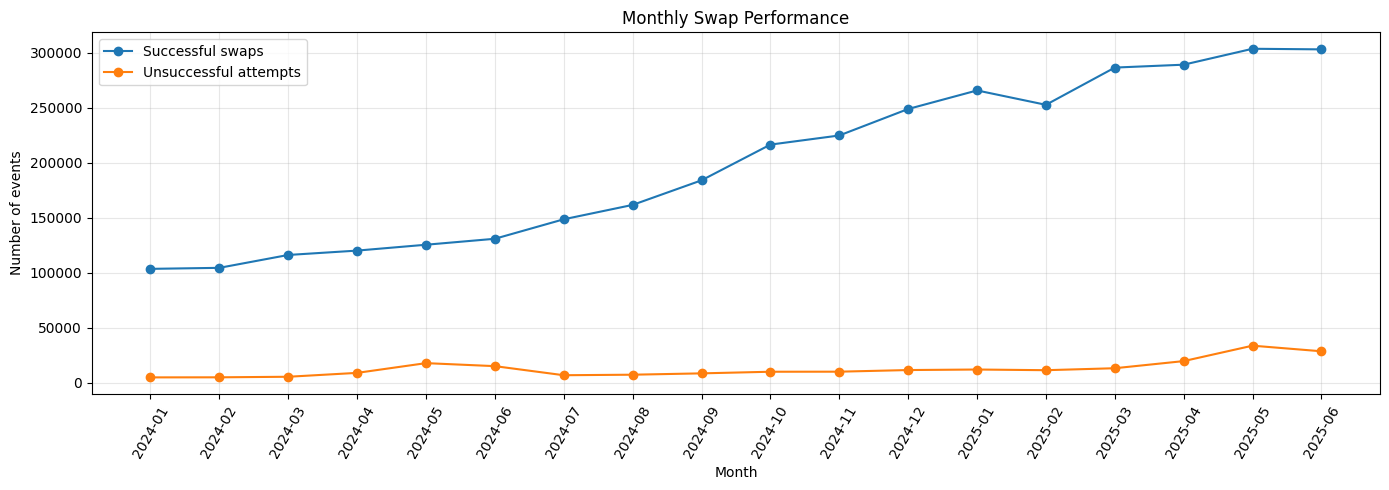

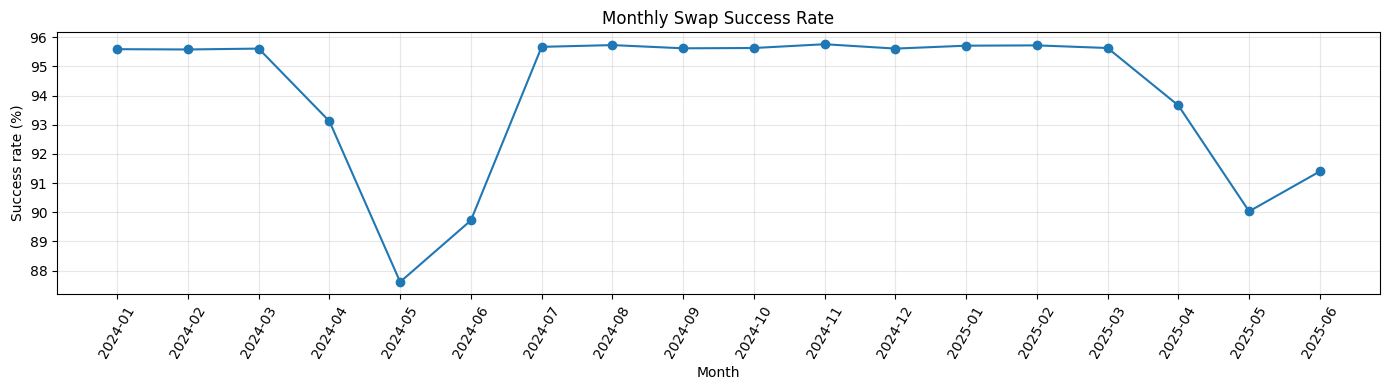

In [34]:
monthly_performance = events_analysis.groupby('month').agg(
    total_attempts=('event_id', 'count'),
    successful_swaps=('is_success', 'sum')
).reset_index()

monthly_performance['unsuccessful_attempts'] = (
    monthly_performance['total_attempts'] - monthly_performance['successful_swaps']
)
monthly_performance['success_rate_pct'] = (
    monthly_performance['successful_swaps'] / monthly_performance['total_attempts'] * 100
).round(2)

display(monthly_performance.tail(20))

plt.figure(figsize=(14, 5))
plt.plot(monthly_performance['month'], monthly_performance['successful_swaps'], marker='o', label='Successful swaps')
plt.plot(monthly_performance['month'], monthly_performance['unsuccessful_attempts'], marker='o', label='Unsuccessful attempts')
plt.xticks(rotation=60)
plt.title('Monthly Swap Performance')
plt.xlabel('Month')
plt.ylabel('Number of events')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 4))
plt.plot(monthly_performance['month'], monthly_performance['success_rate_pct'], marker='o')
plt.xticks(rotation=60)
plt.title('Monthly Swap Success Rate')
plt.xlabel('Month')
plt.ylabel('Success rate (%)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 5.4: Failure reasons and service experience

Queue time and failure reason help identify where the customer experience is breaking down.

,event_type,attempts,avg_queue_wait_sec,share_of_all_failures_pct
0,failed_no_charged_battery,132786,29.496310,58.16
1,abandoned_queue,67663,702.789161,29.64
2,cancelled_by_rider,16458,44.583424,7.21
3,failed_system_error,11400,44.425877,4.99


,is_success,count,mean,median,event_result
0,False,228307,230.872155,45.0,Unsuccessful
1,True,3586675,243.718015,209.0,Successful


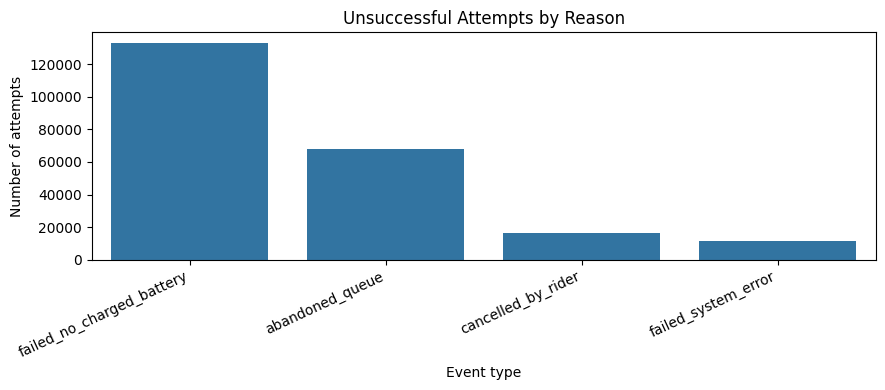

In [35]:
failure_analysis = (
    events_analysis[~events_analysis['is_success']]
    .groupby('event_type')
    .agg(attempts=('event_id', 'count'),
         avg_queue_wait_sec=('queue_wait_sec', 'mean'))
    .sort_values('attempts', ascending=False)
    .reset_index()
)
failure_analysis['share_of_all_failures_pct'] = (
    failure_analysis['attempts'] / max(unsuccessful_attempts, 1) * 100
).round(2)
display(failure_analysis)

queue_summary = events_analysis.groupby('is_success')['queue_wait_sec'].agg(
    ['count', 'mean', 'median']
).reset_index()
queue_summary['event_result'] = queue_summary['is_success'].map(
    {True: 'Successful', False: 'Unsuccessful'}
)
display(queue_summary)

plt.figure(figsize=(9, 4))
sns.barplot(data=failure_analysis, x='event_type', y='attempts')
plt.xticks(rotation=25, ha='right')
plt.title('Unsuccessful Attempts by Reason')
plt.xlabel('Event type')
plt.ylabel('Number of attempts')
plt.tight_layout()
plt.show()

## Step 5.5: City and station performance

Compare cities and identify stations with high unsuccessful-attempt rates. Very low-volume stations should be interpreted carefully.

,city,total_attempts,successful_swaps,avg_queue_wait_sec,unsuccessful_attempts,success_rate_pct,failure_rate_pct
1,Delhi NCR,768913,712385,242.722361,56528,92.65,7.35
0,Bengaluru,763296,728563,242.874410,34733,95.45,4.55
2,Hyderabad,711930,664312,242.785407,47618,93.31,6.69
5,Pune,552910,525331,243.007462,27579,95.01,4.99
4,Mumbai,530299,506718,243.244164,23581,95.55,4.45
3,Jaipur,487634,449366,243.276693,38268,92.15,7.85


Stations with highest failure rate (minimum 500 attempts):


,station_id,city,zone,total_attempts,successful_swaps,avg_queue_wait_sec,failure_rate_pct
36,STN-DEL-037,Delhi NCR,DEL-Noida,30838,28039,242.635871,9.08
47,STN-DEL-048,Delhi NCR,DEL-West,34646,31535,243.989119,8.98
92,STN-JAI-137,Jaipur,JAI-Malviya Nagar,44371,40490,242.782583,8.75
97,STN-JAI-142,Jaipur,JAI-Vaishali,33319,30405,244.333623,8.75
96,STN-JAI-141,Jaipur,JAI-Malviya Nagar,45594,41613,243.734088,8.73
44,STN-DEL-045,Delhi NCR,DEL-Noida,32237,29426,243.086795,8.72
91,STN-JAI-136,Jaipur,JAI-Malviya Nagar,29340,26785,241.874131,8.71
93,STN-JAI-138,Jaipur,JAI-Malviya Nagar,48945,44703,243.439636,8.67
39,STN-DEL-040,Delhi NCR,DEL-South,40335,36848,242.694236,8.65
42,STN-DEL-043,Delhi NCR,DEL-East,49597,45326,243.276166,8.61


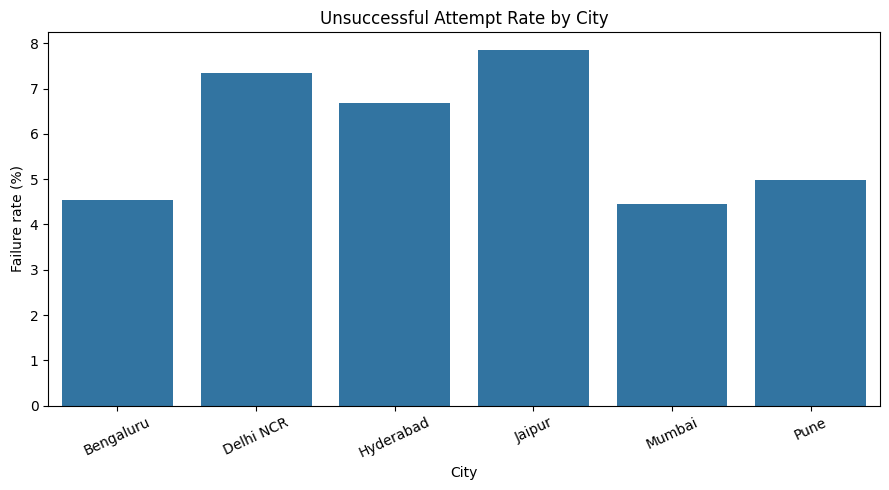

In [36]:
event_station = events_analysis.merge(
    operating_stations[['station_id', 'city', 'zone', 'location_type', 'host_type']],
    on='station_id', how='left'
)

city_performance = event_station.groupby('city').agg(
    total_attempts=('event_id', 'count'),
    successful_swaps=('is_success', 'sum'),
    avg_queue_wait_sec=('queue_wait_sec', 'mean')
).reset_index()
city_performance['unsuccessful_attempts'] = (
    city_performance['total_attempts'] - city_performance['successful_swaps']
)
city_performance['success_rate_pct'] = (
    city_performance['successful_swaps'] / city_performance['total_attempts'] * 100
).round(2)
city_performance['failure_rate_pct'] = (
    100 - city_performance['success_rate_pct']
).round(2)
display(city_performance.sort_values('total_attempts', ascending=False))

station_performance = event_station.groupby(
    ['station_id', 'city', 'zone']
).agg(
    total_attempts=('event_id', 'count'),
    successful_swaps=('is_success', 'sum'),
    avg_queue_wait_sec=('queue_wait_sec', 'mean')
).reset_index()
station_performance['failure_rate_pct'] = (
    (station_performance['total_attempts'] - station_performance['successful_swaps'])
    / station_performance['total_attempts'] * 100
).round(2)

station_performance = station_performance[
    station_performance['total_attempts'] >= 500
].sort_values('failure_rate_pct', ascending=False)

print("Stations with highest failure rate (minimum 500 attempts):")
display(station_performance.head(15))

plt.figure(figsize=(9, 5))
sns.barplot(data=city_performance, x='city', y='failure_rate_pct')
plt.title('Unsuccessful Attempt Rate by City')
plt.xlabel('City')
plt.ylabel('Failure rate (%)')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## Step 5.6: Peak-hour demand and queue pressure

This identifies busy hours and helps plan staffing, inventory, and charging capacity.

,hour,attempts,successful_swaps,avg_queue_wait_sec,failure_rate_pct
0,0,22010,20781,243.360245,5.58
1,1,21786,20571,245.058019,5.58
2,2,21921,20697,243.023722,5.58
3,3,21892,20682,243.303810,5.53
4,4,24838,23526,241.549199,5.28
5,5,24717,23385,243.705628,5.39
6,6,54658,51607,242.556570,5.58
7,7,54919,51854,244.006919,5.58
8,8,164669,155298,242.865646,5.69
9,9,232722,219715,242.534599,5.59


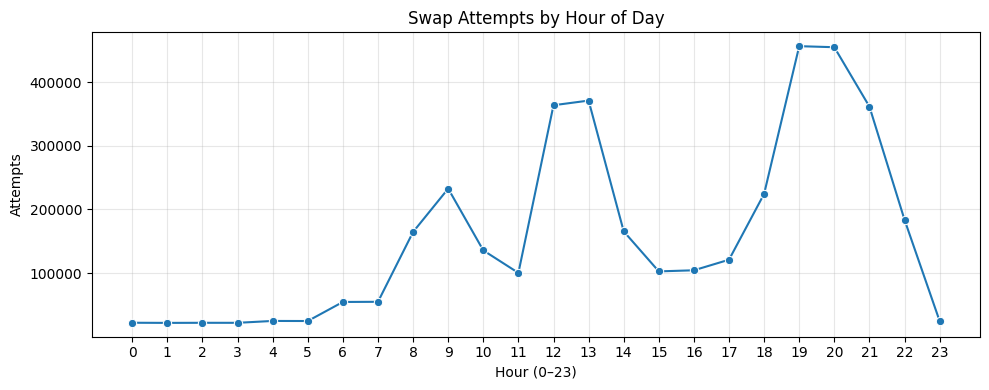

In [37]:
hourly_performance = events_analysis.groupby('hour').agg(
    attempts=('event_id', 'count'),
    successful_swaps=('is_success', 'sum'),
    avg_queue_wait_sec=('queue_wait_sec', 'mean')
).reset_index()
hourly_performance['failure_rate_pct'] = (
    (hourly_performance['attempts'] - hourly_performance['successful_swaps'])
    / hourly_performance['attempts'] * 100
).round(2)
display(hourly_performance)

plt.figure(figsize=(10, 4))
sns.lineplot(data=hourly_performance, x='hour', y='attempts', marker='o')
plt.title('Swap Attempts by Hour of Day')
plt.xlabel('Hour (0–23)')
plt.ylabel('Attempts')
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 5.7: Rider retention analysis

A rider is treated as retained at 30 days if they make another completed swap within 30 days after their first completed swap. This is a simple behavioural definition, not a formal contractual churn label.

In [38]:
completed_events = events_analysis[
    events_analysis['is_success']
][['rider_id', 'event_ts_corrected']].copy()

completed_events['first_swap_date'] = (
    completed_events.groupby('rider_id')['event_ts_corrected'].transform('min')
)

completed_events['days_from_first_swap'] = (
    completed_events['event_ts_corrected'] - completed_events['first_swap_date']
).dt.total_seconds() / 86400

rider_retention = completed_events.groupby('rider_id').agg(
    first_swap_date=('first_swap_date', 'min'),
    swaps_in_first_30_days=('days_from_first_swap', lambda x: ((x > 0) & (x <= 30)).sum()),
    total_completed_swaps=('event_ts_corrected', 'count')
).reset_index()

rider_retention['retained_30d'] = rider_retention['swaps_in_first_30_days'] > 0
retention_rate = rider_retention['retained_30d'].mean() * 100

print("Riders with at least one completed swap:", len(rider_retention))
print("30-day repeat activity rate (%):", round(retention_rate, 2))

# Signup cohort by month, based on rider signup date
rider_cohort = riders_clean[['rider_id', 'signup_date', 'signup_channel', 'plan_type', 'partner_id']].merge(
    rider_retention[['rider_id', 'retained_30d']], on='rider_id', how='left'
)
rider_cohort['retained_30d'] = rider_cohort['retained_30d'].fillna(False)
rider_cohort['signup_month'] = rider_cohort['signup_date'].dt.to_period('M').astype(str)

cohort_summary = rider_cohort.groupby('signup_month').agg(
    riders=('rider_id', 'count'),
    retained_riders=('retained_30d', 'sum')
).reset_index()
cohort_summary['retention_rate_pct'] = (
    cohort_summary['retained_riders'] / cohort_summary['riders'] * 100
).round(2)
display(cohort_summary.tail(20))

channel_retention = rider_cohort.groupby('signup_channel').agg(
    riders=('rider_id', 'count'),
    retained_riders=('retained_30d', 'sum')
).reset_index()
channel_retention['retention_rate_pct'] = (
    channel_retention['retained_riders'] / channel_retention['riders'] * 100
).round(2)
display(channel_retention.sort_values('retention_rate_pct'))

Riders with at least one completed swap: 19938
30-day repeat activity rate (%): 99.31


/tmp/ipykernel_4061/532164041.py:29: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rider_cohort['retained_30d'] = rider_cohort['retained_30d'].fillna(False)


,signup_month,riders,retained_riders,retention_rate_pct
8,2023-11,405,405,100.00
9,2023-12,24,24,100.00
10,2024-01,601,596,99.17
11,2024-02,567,564,99.47
12,2024-03,601,593,98.67
13,2024-04,663,656,98.94
14,2024-05,722,716,99.17
15,2024-06,716,711,99.30
16,2024-07,811,804,99.14
17,2024-08,856,851,99.42


,signup_channel,riders,retained_riders,retention_rate_pct
3,referral,2265,2241,98.94
0,app_store,4215,4172,98.98
2,partner_onboarding,9376,9282,99.00
1,field_agent,4144,4105,99.06


## Step 5.8: Support tickets and customer experience

We review ticket categories, resolution time, status, and CSAT. CSAT is calculated only where a score is present because missing scores are not random.

,category,tickets,avg_resolution_hours,avg_csat
4,no_battery_available,11647,15.961265,3.602452
5,other,9484,16.036723,3.567468
3,low_range,6636,15.990958,3.531183
0,app_issue,5787,15.894224,3.539805
2,long_queue,5731,15.842201,3.506520
1,billing_dispute,4715,15.908325,3.569136


Tickets with a CSAT score: 15129
Overall average CSAT (scored tickets only): 3.56


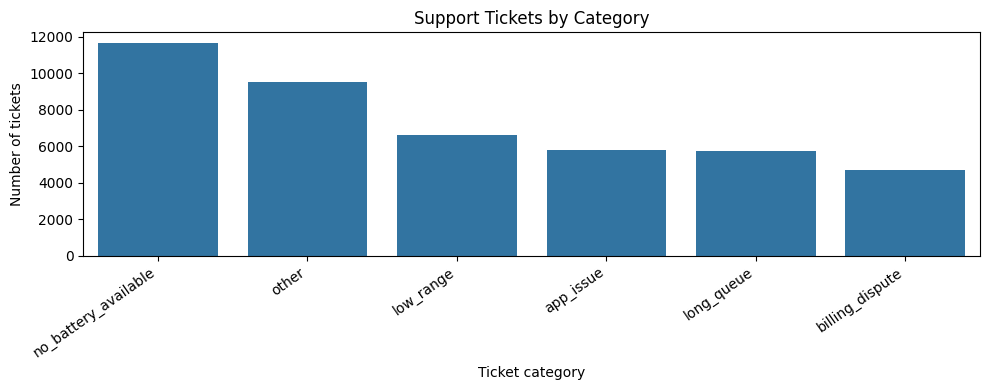

,resolution_status,tickets
0,resolved,37888
1,unresolved,5175
2,duplicate,937


In [39]:
tickets_analysis = support_tickets_clean.merge(
    riders_clean[['rider_id', 'partner_id', 'home_city_std']],
    on='rider_id', how='left'
)

ticket_categories = tickets_analysis.groupby('category').agg(
    tickets=('ticket_id', 'count'),
    avg_resolution_hours=('resolution_hours', 'mean'),
    avg_csat=('csat_score', 'mean')
).reset_index().sort_values('tickets', ascending=False)
display(ticket_categories)

print("Tickets with a CSAT score:", tickets_analysis['csat_score'].notna().sum())
print("Overall average CSAT (scored tickets only):", round(tickets_analysis['csat_score'].mean(), 2))

plt.figure(figsize=(10, 4))
sns.barplot(data=ticket_categories.head(10), x='category', y='tickets')
plt.xticks(rotation=35, ha='right')
plt.title('Support Tickets by Category')
plt.xlabel('Ticket category')
plt.ylabel('Number of tickets')
plt.tight_layout()
plt.show()

resolution_status = tickets_analysis['resolution_status'].value_counts().reset_index()
resolution_status.columns = ['resolution_status', 'tickets']
display(resolution_status)

## Step 5.9: Battery health and equipment analysis

Battery health is reviewed by pack type and supplier. This is descriptive analysis; it does not prove that supplier or battery age caused a swap failure.

,pack_type,supplier,batteries,avg_current_soh,avg_initial_soh,avg_purchase_cost
0,2W_2.1kWh,Amptek,1098,79.96,99.19,31995.05
1,2W_2.1kWh,Cellora,3035,79.97,99.18,31983.39
2,2W_2.1kWh,Kyron,1385,60.53,99.20,31981.68
3,3W_4.8kWh,Amptek,209,86.51,99.20,67822.26
4,3W_4.8kWh,Cellora,520,86.52,99.20,67957.39
5,3W_4.8kWh,Kyron,253,81.35,99.25,67920.95


,supplier,swap_events,avg_battery_soh,avg_queue_wait_sec
0,Amptek,784958,80.61,243.75
1,Cellora,2148863,80.57,243.78
2,Kyron,652854,63.61,243.49


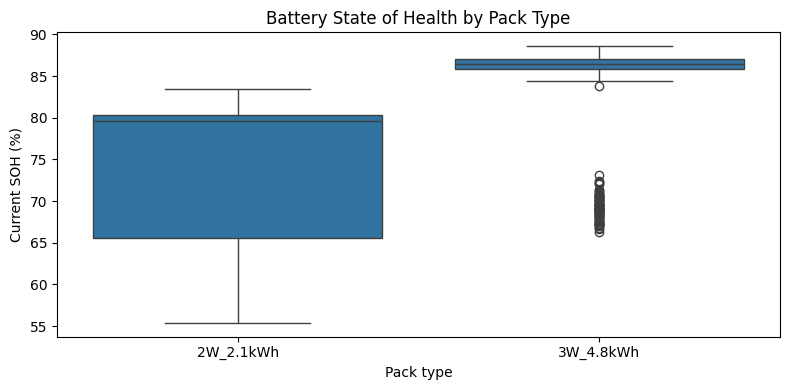

In [40]:
battery_summary = batteries_clean.groupby(['pack_type', 'supplier']).agg(
    batteries=('battery_id', 'count'),
    avg_current_soh=('current_soh_pct', 'mean'),
    avg_initial_soh=('initial_soh_pct', 'mean'),
    avg_purchase_cost=('purchase_cost_inr', 'mean')
).reset_index()
display(battery_summary.round(2))

battery_swap = events_analysis.merge(
    batteries_clean[['battery_id', 'pack_type', 'supplier', 'current_soh_pct']],
    left_on='battery_out_id', right_on='battery_id', how='left'
)

battery_event_summary = battery_swap.groupby('supplier').agg(
    swap_events=('event_id', 'count'),
    avg_battery_soh=('current_soh_pct', 'mean'),
    avg_queue_wait_sec=('queue_wait_sec', 'mean')
).reset_index()
display(battery_event_summary.round(2))

plt.figure(figsize=(8, 4))
sns.boxplot(data=batteries_clean, x='pack_type', y='current_soh_pct')
plt.title('Battery State of Health by Pack Type')
plt.xlabel('Pack type')
plt.ylabel('Current SOH (%)')
plt.tight_layout()
plt.show()

## Step 5.10: Fleet partner performance and pricing

Partner-level results use completed swaps and observed amount charged. Revenue here means recorded amount charged, not gross list price. Partner comparisons should consider differences in fleet size and activity.

In [41]:
completed_partner_events = events_analysis[
    events_analysis['is_success']
].merge(
    riders_clean[['rider_id', 'partner_id']],
    on='rider_id', how='left'
).merge(
    fleet_partners_clean[['partner_id', 'partner_name', 'partner_segment',
                          'contract_type', 'discount_pct', 'discount_pct_after_amendment']],
    on='partner_id', how='left'
)

partner_performance = completed_partner_events.groupby(
    ['partner_id', 'partner_name', 'partner_segment', 'contract_type']
).agg(
    completed_swaps=('event_id', 'count'),
    recorded_revenue_inr=('amount_charged_inr', 'sum'),
    avg_amount_charged_inr=('amount_charged_inr', 'mean'),
    avg_discount_inr=('discount_inr', 'mean'),
    avg_queue_wait_sec=('queue_wait_sec', 'mean')
).reset_index().sort_values('recorded_revenue_inr', ascending=False)

display(partner_performance.round(2))

,partner_id,partner_name,partner_segment,contract_type,completed_swaps,recorded_revenue_inr,avg_amount_charged_inr,avg_discount_inr,avg_queue_wait_sec
0,FP-01,FeastFly,food_delivery,volume_tiered,516367,32027884.50,62.03,6.64,243.37
2,FP-03,ZipDrop,quick_commerce,volume_tiered,549390,28606514.80,52.07,14.62,243.88
1,FP-02,ParcelNest,ecom_logistics,pay_per_swap,296209,16740212.75,56.51,9.94,244.17
4,FP-05,Swiggle Go,food_delivery,volume_tiered,237632,14092428.90,59.30,7.33,244.16
3,FP-04,CargoTuk,cargo_3w,pay_per_swap,131334,13062630.80,99.46,8.64,243.31
6,FP-07,QuickCart,quick_commerce,pay_per_swap,127961,7934508.55,62.01,5.92,244.12
5,FP-06,RideMitra,bike_taxi,pay_per_swap,119503,7494595.50,62.71,3.96,243.83
7,FP-08,DabbaXpress,food_delivery,pay_per_swap,92027,5853723.60,63.61,5.32,243.05
8,FP-09,HaulKing,cargo_3w,pay_per_swap,53120,5331093.20,100.36,7.55,243.09
11,FP-12,UrbanErrand,bike_taxi,pay_per_swap,82363,5226978.50,63.46,3.30,244.07


## Step 5.11: Energy cost and contribution proxy

A complete contribution-margin calculation requires all variable and allocated costs. The supplied data supports an **energy-cost proxy** using recharge kWh and station grid tariff. We therefore do not label this as actual contribution margin.

The station rent and maintenance fields are fixed monthly costs; they are shown separately and should be allocated carefully before calculating a true per-swap margin.

In [45]:
completed_station_events = events_analysis[
    events_analysis['is_success']
].merge(
    operating_stations[['station_id', 'city', 'grid_tariff_inr_kwh',
                        'monthly_rent_inr', 'monthly_maintenance_inr']],
    on='station_id', how='left'
)

completed_station_events['estimated_energy_cost_inr'] = (
    completed_station_events['energy_to_recharge_kwh'] *
    completed_station_events['grid_tariff_inr_kwh']
)

economics_summary = completed_station_events.agg(
    completed_swaps=('event_id', 'count'),
    recorded_revenue_inr=('amount_charged_inr', 'sum'),
    estimated_energy_kwh=('energy_to_recharge_kwh', 'sum'),
    estimated_energy_cost_inr=('estimated_energy_cost_inr', 'sum')
)

# Transpose to display it in a vertical key-value table format
economics_summary = economics_summary.T.rename(columns={0: 'Value'})
display(economics_summary)

economics_by_city = completed_station_events.groupby('city').agg(
    completed_swaps=('event_id', 'count'),
    recorded_revenue_inr=('amount_charged_inr', 'sum'),
    estimated_energy_cost_inr=('estimated_energy_cost_inr', 'sum')
).reset_index()
economics_by_city['revenue_after_energy_cost_proxy'] = (
    economics_by_city['recorded_revenue_inr'] -
    economics_by_city['estimated_energy_cost_inr']
)
display(economics_by_city.sort_values('revenue_after_energy_cost_proxy', ascending=False))

,completed_swaps,recorded_revenue_inr,estimated_energy_kwh,estimated_energy_cost_inr
event_id,3586675.0,NaN,NaN,NaN
amount_charged_inr,NaN,229195295.5,NaN,NaN
energy_to_recharge_kwh,NaN,NaN,7503291.965,NaN
estimated_energy_cost_inr,NaN,NaN,NaN,6.991776e+07


,city,completed_swaps,recorded_revenue_inr,estimated_energy_cost_inr,revenue_after_energy_cost_proxy
0,Bengaluru,728563,48023983.20,1.411198e+07,3.391200e+07
1,Delhi NCR,712385,44565107.85,1.345959e+07,3.110552e+07
2,Hyderabad,664312,41521622.25,1.266184e+07,2.885978e+07
5,Pune,525331,34766281.90,9.912458e+06,2.485382e+07
4,Mumbai,506718,32089247.45,1.106720e+07,2.102205e+07
3,Jaipur,449366,28229052.85,8.704691e+06,1.952436e+07


## Step 5.12: Station availability and telemetry

Missing telemetry is not replaced with zero. We compare telemetry status and observed outage minutes for operating stations only.

telemetry_status,missing,ok,partial
city,,,
Bengaluru,1938,307316,6874
Delhi NCR,2219,281992,8253
Hyderabad,628,250882,5314
Jaipur,1702,163241,5577
Mumbai,1346,203528,5606
Pune,1551,208366,5123


,city,observed_hours,total_outage_minutes,avg_outage_minutes
4,Mumbai,210480,7080,0.033637
1,Delhi NCR,292464,3420,0.011694
0,Bengaluru,316128,2220,0.007022
5,Pune,215040,2160,0.010045
3,Jaipur,170520,2040,0.011963
2,Hyderabad,256824,1260,0.004906


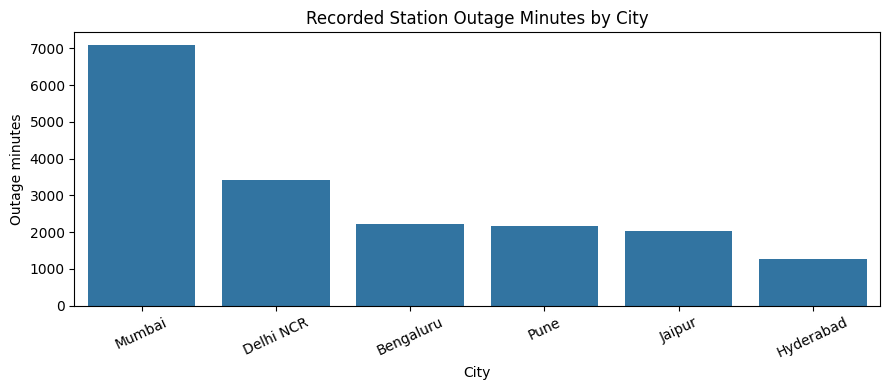

In [46]:
station_status_analysis = station_hourly_status_clean.merge(
    operating_stations[['station_id', 'city']], on='station_id', how='inner'
)

telemetry_summary = station_status_analysis.groupby(['city', 'telemetry_status']).size().unstack(fill_value=0)
display(telemetry_summary)

outage_by_city = station_status_analysis.groupby('city').agg(
    observed_hours=('hour_start', 'count'),
    total_outage_minutes=('outage_minutes', 'sum'),
    avg_outage_minutes=('outage_minutes', 'mean')
).reset_index().sort_values('total_outage_minutes', ascending=False)
display(outage_by_city)

plt.figure(figsize=(9, 4))
sns.barplot(data=outage_by_city, x='city', y='total_outage_minutes')
plt.title('Recorded Station Outage Minutes by City')
plt.xlabel('City')
plt.ylabel('Outage minutes')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## Step 5.13: Business insights and recommendations

After running all analysis cells, use the displayed tables and charts to write evidence-based findings. Avoid claiming causation from descriptive comparisons.

Suggested action areas to evaluate:
1. Prioritize stations and time slots with high unsuccessful-attempt rates and long queues.
2. Improve charged-battery availability where `failed_no_charged_battery` is a major failure reason.
3. Review city and acquisition-channel cohorts with weaker 30-day repeat activity.
4. Investigate ticket categories with high volume and long resolution times.
5. Monitor battery SOH and quarantine patterns; investigate weak-performing lots before replacement decisions.
6. Review partner discount structures alongside recorded revenue and energy-cost proxy.
7. Improve telemetry completeness before using station-level availability metrics for operational decisions.

**Do not present the energy-cost proxy as actual contribution margin.** A full margin requires all variable costs and a defensible allocation of fixed station costs.

# Failure Pareto Analysis –  important

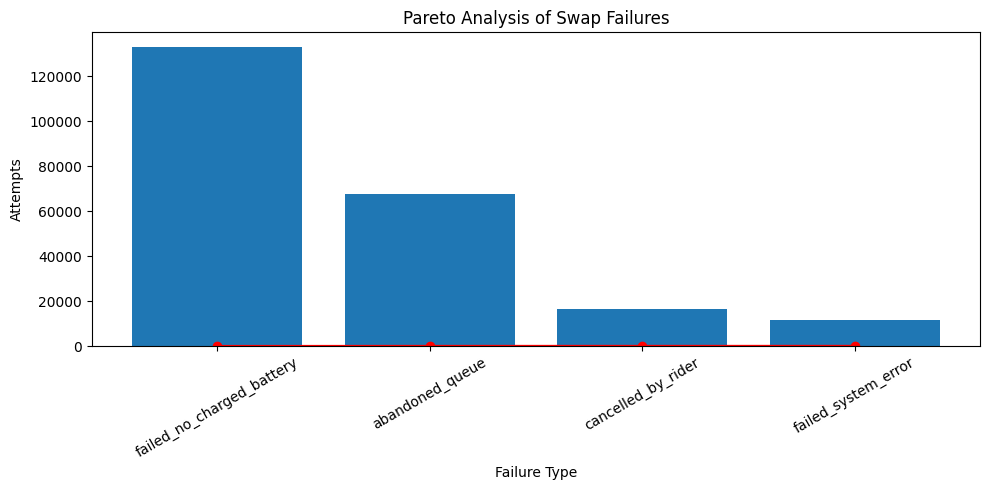

,event_type,attempts,avg_queue_wait_sec,share_of_all_failures_pct,cumulative_pct
0,failed_no_charged_battery,132786,29.496310,58.16,58.161160
1,abandoned_queue,67663,702.789161,29.64,87.798009
2,cancelled_by_rider,16458,44.583424,7.21,95.006723
3,failed_system_error,11400,44.425877,4.99,100.000000


In [47]:
# Failure Pareto Analysis

pareto = failure_analysis.sort_values(
    'attempts', ascending=False
).copy()

pareto['cumulative_pct'] = (
    pareto['attempts'].cumsum() /
    pareto['attempts'].sum() * 100
)

plt.figure(figsize=(10, 5))

plt.bar(pareto['event_type'], pareto['attempts'])
plt.plot(
    pareto['event_type'],
    pareto['cumulative_pct'],
    marker='o',
    color='red'
)

plt.title('Pareto Analysis of Swap Failures')
plt.xlabel('Failure Type')
plt.ylabel('Attempts')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(pareto)

## Station Priority Matrix

In [48]:
# Station Priority Analysis

station_priority = station_performance[
    station_performance['total_attempts'] >= 500
].copy()

station_priority['priority_score'] = (
    station_priority['failure_rate_pct'] *
    np.log1p(station_priority['total_attempts'])
)

station_priority = station_priority.sort_values(
    'priority_score', ascending=False
)

display(
    station_priority[
        ['station_id', 'total_attempts',
         'failure_rate_pct', 'priority_score']
    ].head(10)
)

,station_id,total_attempts,failure_rate_pct,priority_score
47,STN-DEL-048,34646,8.98,93.867638
36,STN-DEL-037,30838,9.08,93.855741
96,STN-JAI-141,45594,8.73,93.651541
92,STN-JAI-137,44371,8.75,93.628184
93,STN-JAI-138,48945,8.67,93.622760
42,STN-DEL-043,49597,8.61,93.088787
49,STN-DEL-050,47060,8.61,92.636711
39,STN-DEL-040,40335,8.65,91.733247
97,STN-JAI-142,33319,8.75,91.121740
44,STN-DEL-045,32237,8.72,90.521458


# KPI Monitoring Dashboard

In [49]:
# KPI Monitoring Plan

kpi_monitoring = pd.DataFrame({
    'KPI': [
        'Failure Rate',
        '30-Day Repeat Activity',
        'Support Ticket Volume',
        'Telemetry Completeness'
    ],
    'Current Baseline': [
        round((~events_analysis['is_success']).mean() * 100, 2),
        round(retention_rate, 2),
        len(tickets_analysis),
        round(
            station_status_analysis['telemetry_status']
            .eq('complete').mean() * 100, 2
        )
    ],
    'Review Frequency': [
        'Weekly', 'Monthly', 'Monthly', 'Weekly'
    ]
})

display(kpi_monitoring)

,KPI,Current Baseline,Review Frequency
0,Failure Rate,5.98,Weekly
1,30-Day Repeat Activity,99.31,Monthly
2,Support Ticket Volume,44000.00,Monthly
3,Telemetry Completeness,0.00,Weekly


# Overall Network Performance

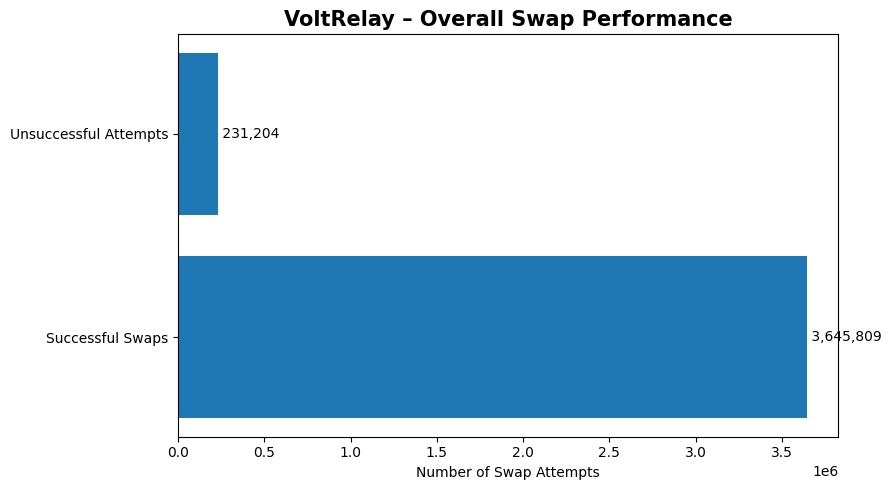

In [50]:


labels = ['Successful Swaps', 'Unsuccessful Attempts']
values = [3645809, 231204]

plt.figure(figsize=(9, 5))

bars = plt.barh(labels, values)

plt.title('VoltRelay – Overall Swap Performance',
          fontsize=15, fontweight='bold')
plt.xlabel('Number of Swap Attempts')

for bar, value in zip(bars, values):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        f' {value:,}',
        va='center'
    )

plt.tight_layout()
plt.show()

# Final Conclusion – Turning Data into Better Decisions

VoltRelay has successfully built a high-volume battery-swapping network, recording **3.87 million swap attempts**. However, growth alone is not enough — reliability, customer retention and profitability must grow together.

### Network Performance at a Glance

| Key Metric | Result |
|---|---:|
| Total Swap Attempts | **3.87 Million** |
| Successful Swaps | **3.65 Million** |
| Unsuccessful Attempts | **2.31 Lakh** |
| Success Rate | **94.04%** |
| Unsuccessful Rate | **5.96%** |

### Our Key Message

**More Swaps. Fewer Failures. Happier Riders. Better Economics.**

To achieve sustainable growth, VoltRelay should focus on:

1. **Improve Reliability:** Reduce recurring swap failures and operational bottlenecks.
2. **Optimize Stations:** Prioritize high-impact stations and improve battery availability.
3. **Retain Riders:** Improve the first-time and repeat-rider experience.
4. **Strengthen Economics:** Monitor energy costs, partner performance and contribution margin.
5. **Track Performance:** Use clear KPIs to measure improvements continuously.

### Final Takeaway

The next stage of VoltRelay's growth should not be measured only by how many swaps it completes, but by how reliably, profitably and consistently it serves its riders.

# **The goal is not just a bigger network — it is a smarter, more reliable and sustainable network.**